In [40]:
#import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [28]:
# load the dataset
df = pd.read_csv("loan_approval_dataset.csv")
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [29]:
# check the info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [30]:
# check for duplicates
df.duplicated().sum()

0

##### The dataset has no duplicate values

In [31]:
#check for missing values
df.isna().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

##### The dataset has no missing values

In [32]:
# check for statistical summary
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [33]:
#check distribution of the target column
df[' loan_status'].value_counts(dropna=False)

 loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

In [34]:
# check names of columns
df.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')

### Visualizing the data

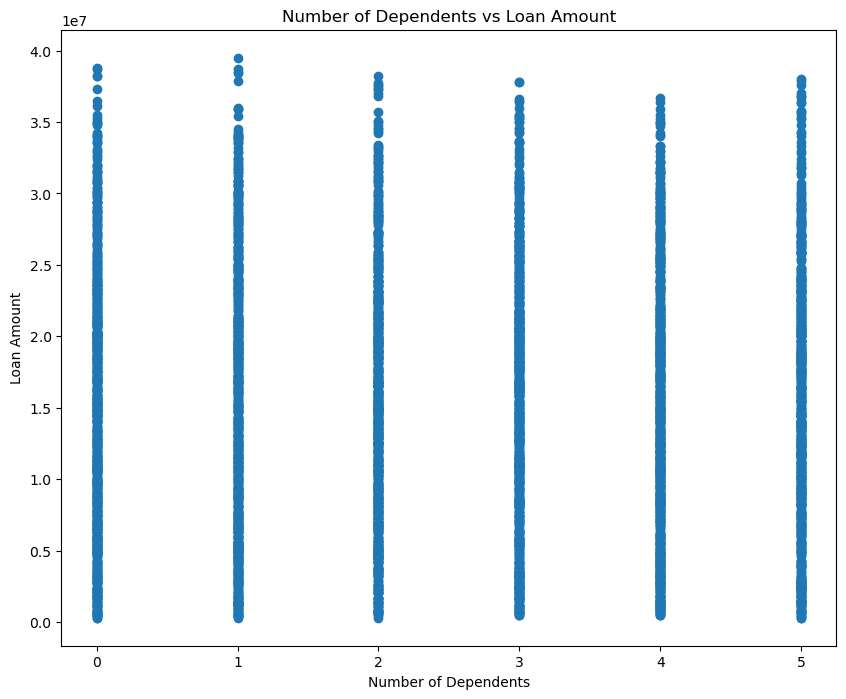

In [38]:
# bar graph of dependents against loan amount
df.columns = df.columns.str.strip()
plt.figure(figsize=(10, 8))
plt.scatter(df['no_of_dependents'], df['loan_amount'])
plt.xlabel("Number of Dependents")
plt.ylabel("Loan Amount")
plt.title("Number of Dependents vs Loan Amount")
plt.show();

#### This chart shows how loan amounts relate to the number of dependents a borrower has. Each column of dots represents people with the same number of dependents. The dots are spread widely up and down, meaning loan amounts vary a lot within each group. In simple terms, having more dependents doesn’t seem to change how big a loan someone gets meaning people with few or many dependents borrow similar amounts.

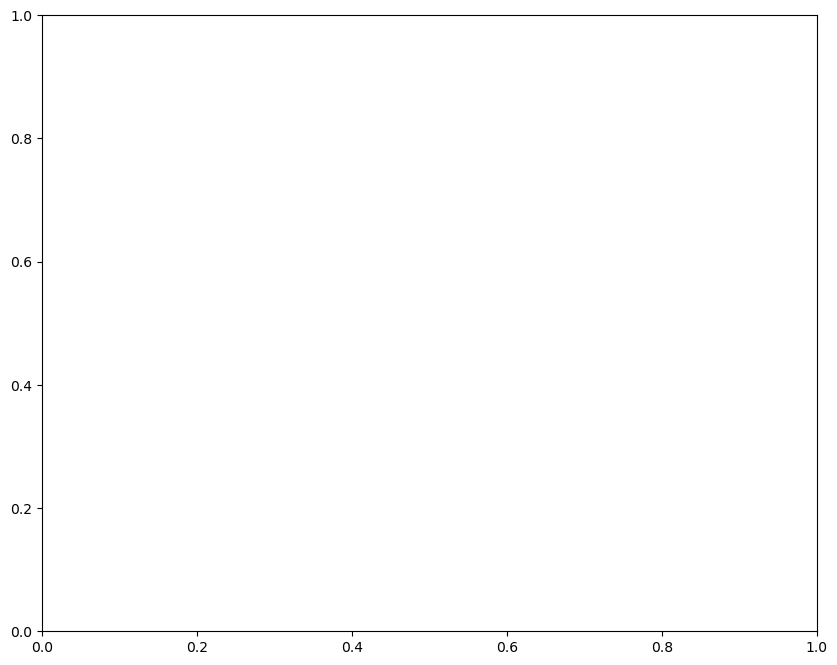

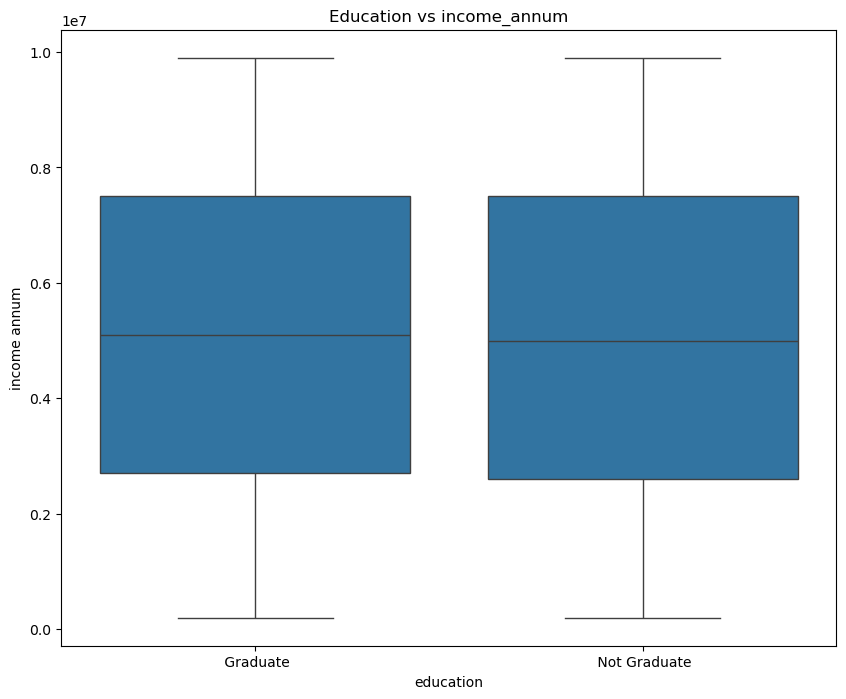

In [41]:
plt.figure(figsize=(10,8))
sns.boxplot(data=df, x='education', y='income_annum')
plt.title('Education vs income_annum')
plt.xlabel('education')
plt.ylabel('income annum')
plt.show();

#### This boxplot compares annual income between graduates and non‑graduates. Both groups show nearly identical medians and similar spreads, meaning education level doesn’t significantly affect income in this dataset. The wide boxes and long whiskers indicate high variability in income within each group, with overlapping distributions suggesting no clear income advantage for graduates.

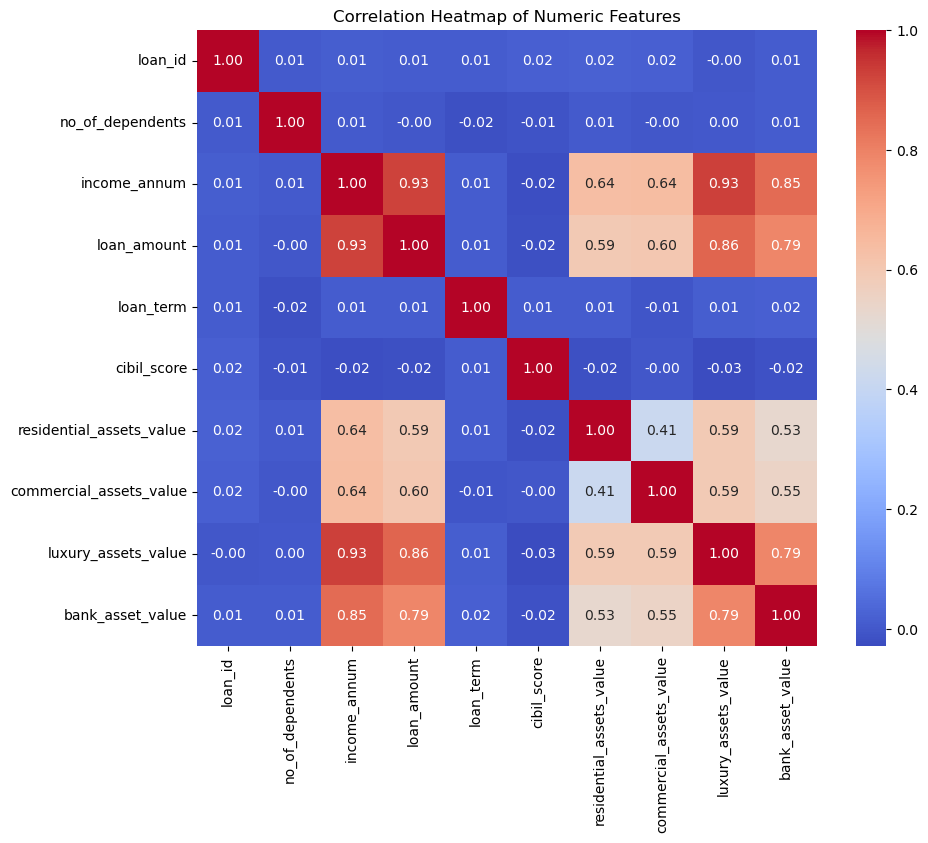

In [46]:
# heatmap for correlations
# Select only numeric columns for correlation
numeric_cols = df.select_dtypes(include=['int64', 'float64'])

# Compute correlation matrix
corr = numeric_cols.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Numeric Features')
plt.show();

## Here’s the interpretation:

### Strong positive correlations:

- income_annum ↔ loan_amount (0.93) — people with higher income tend to take larger loans.

- income_annum ↔ luxury_assets_value (0.93) and bank_asset_value (0.85) — wealthier individuals own more luxury and bank assets.

- loan_amount ↔ luxury_assets_value (0.86) and bank_asset_value (0.79) — larger loans are associated with higher-value assets.

### Moderate correlations:

- residential_assets_value ↔ commercial_assets_value (0.41) — owning residential property moderately relates to owning commercial property.

### Weak or negligible correlations:

- no_of_dependents, loan_term, and cibil_score show very low correlations with most variables, suggesting they vary independently.

- Diagonal values (1.00): Each variable perfectly correlates with itself, as expected.

## Key takeaway:  
Income and asset values tend to move together, suggesting that people with higher incomes often have more valuable assets. However, credit scores and the number of dependents don't show a strong relationship with income or asset values. This suggests they may affect loan approval in other ways rather than being directly linked to how much someone earns or owns.

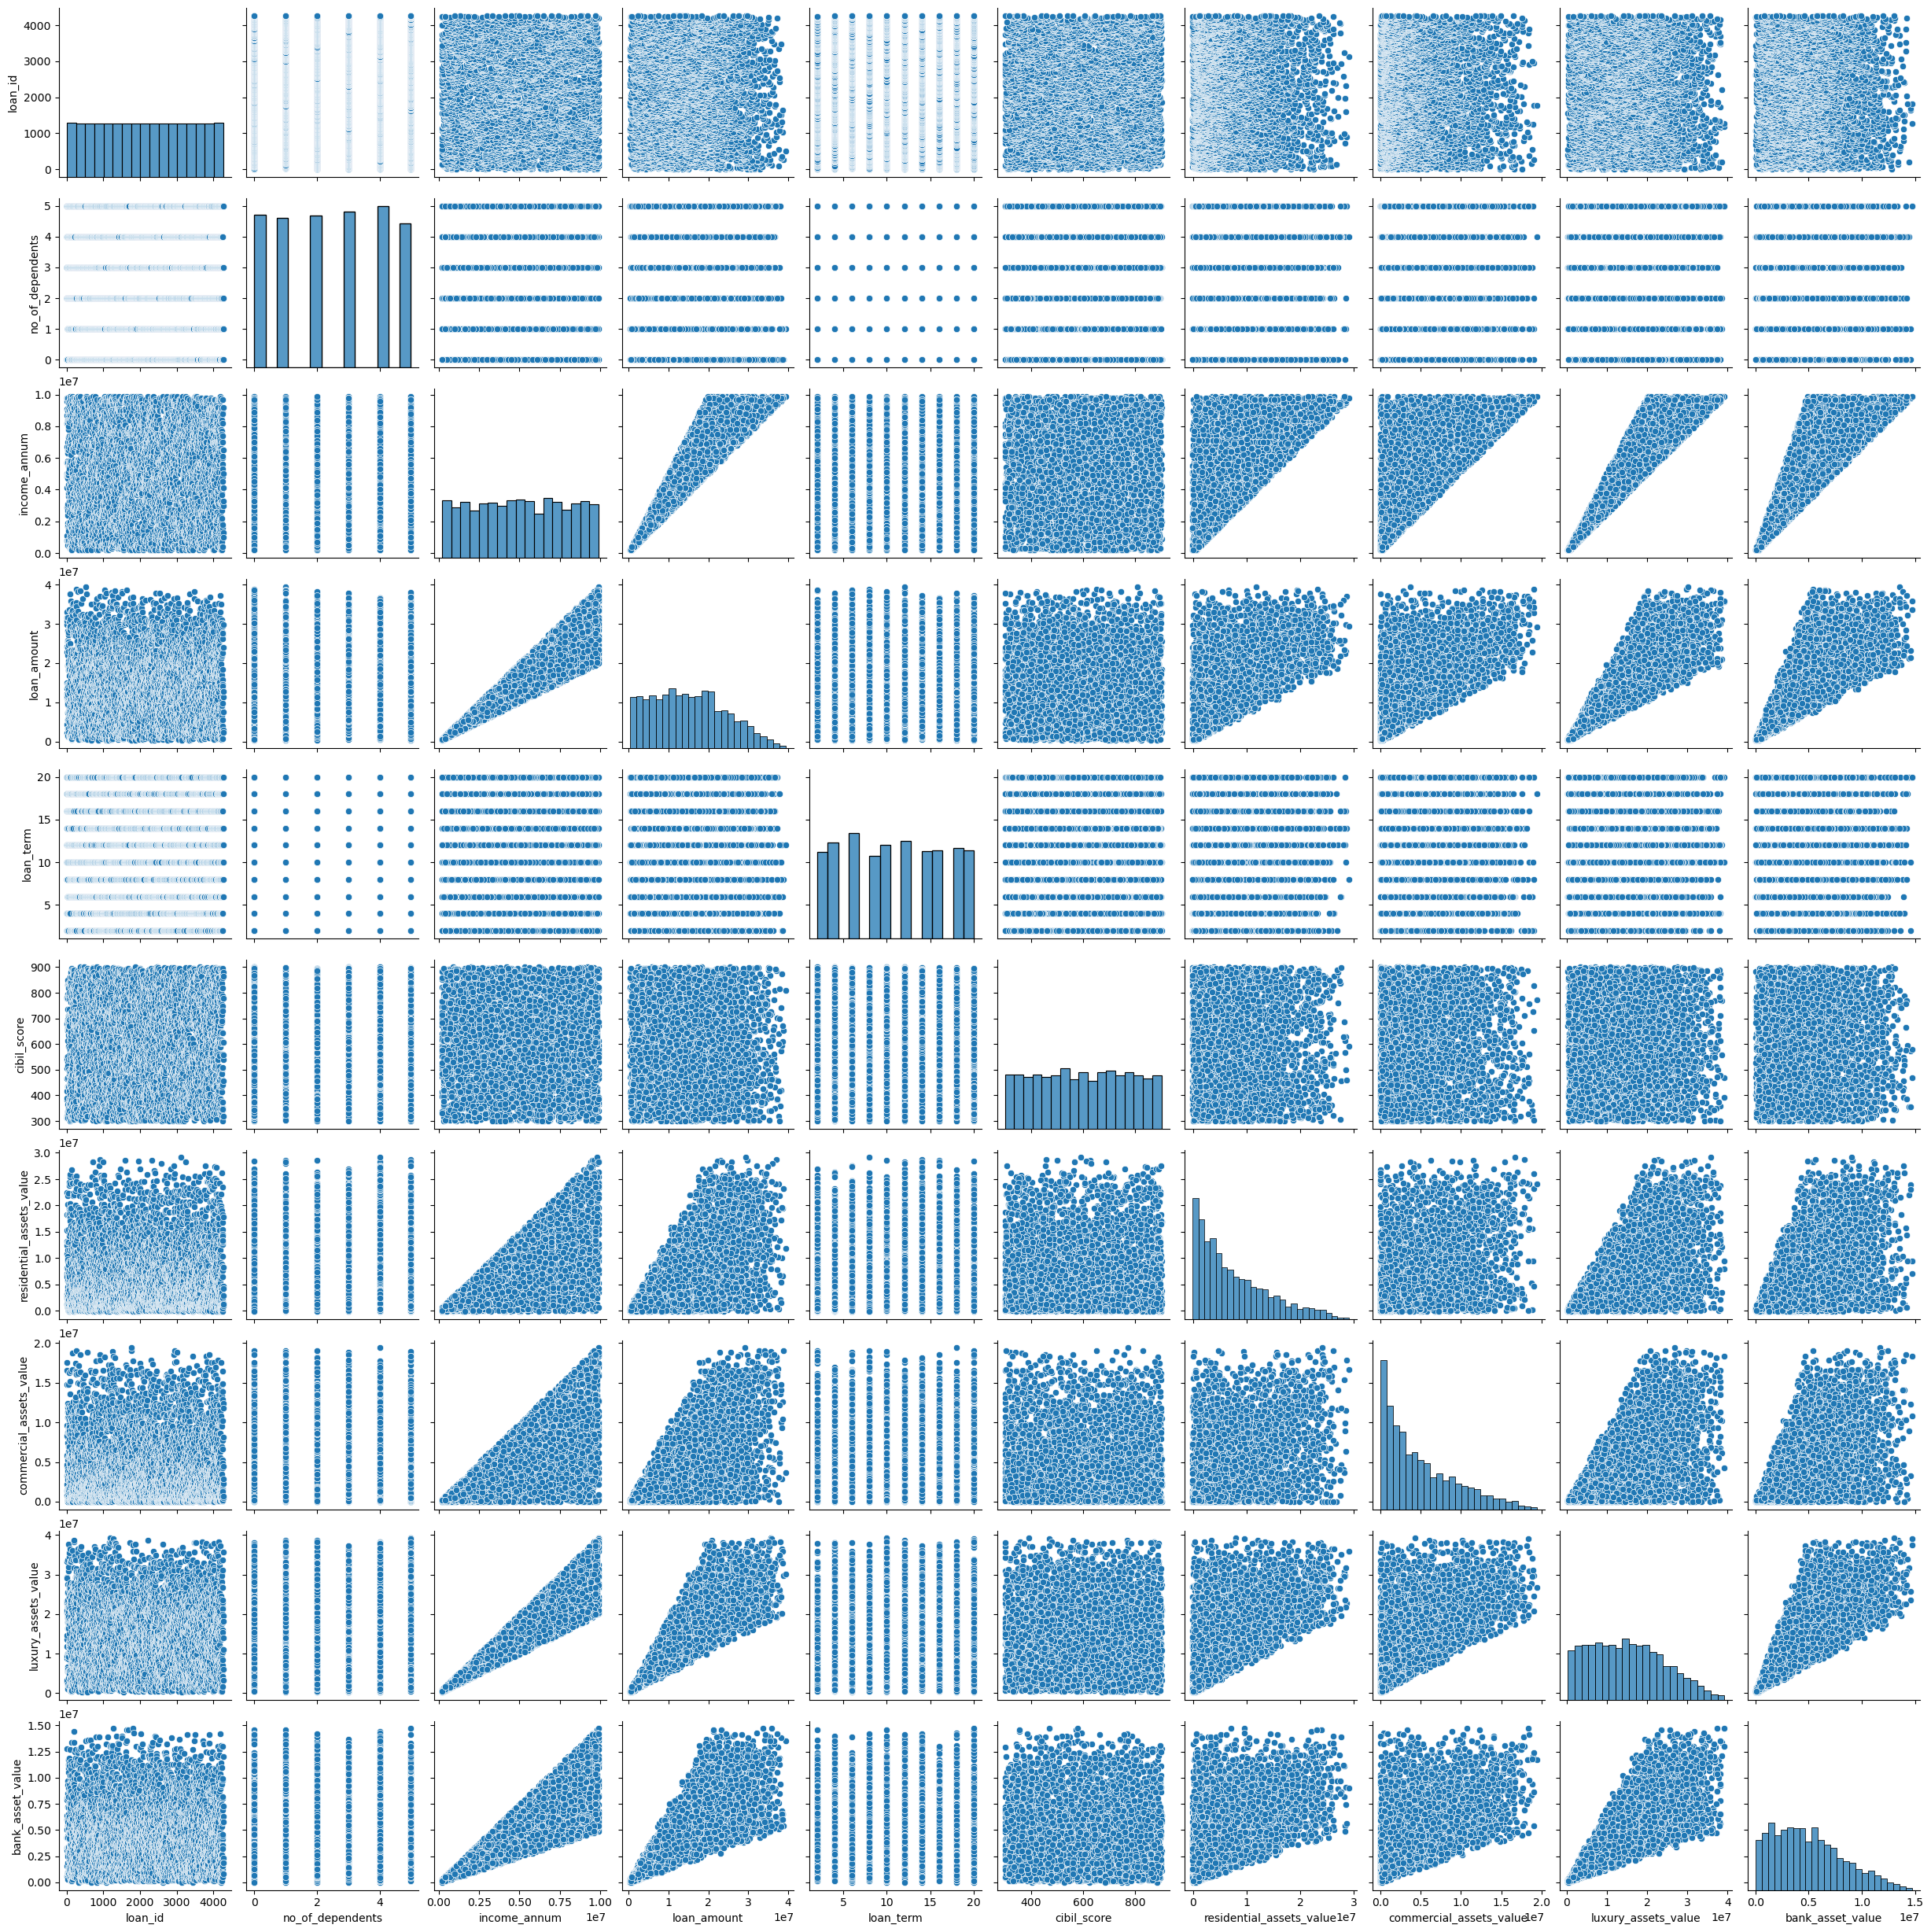

In [47]:
#pairplot for different numerical columns
sns.pairplot(df[numeric_cols.columns])
plt.show()

## Noticeable Trends

- income_annum and loan_amount — higher income corresponds to larger loans.

- income_annum and luxury_assets_value / bank_asset_value — wealthier individuals tend to own more assets.

- loan_amount and asset values — larger loans align with higher asset values.

##### Weak or no visible patterns: Variables like no_of_dependents, loan_term, and cibil_score show scattered points without clear trends, suggesting low correlation with financial magnitude variables.

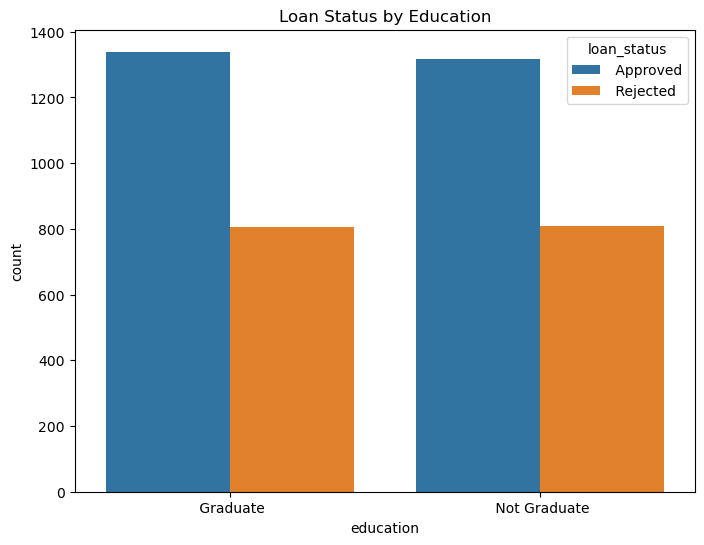

In [50]:
#countplot of education against loan status
plt.figure(figsize=(8, 6))
sns.countplot(x='education', hue='loan_status', data=df)
plt.title('Loan Status by Education')
plt.show()


#### This bar chart shows how loan approvals and rejections differ between graduates and non‑graduates. Both groups have almost the same pattern, more loans are approved than rejected. Graduates have a slightly higher number of approvals, but overall, education level doesn’t seem to make a big difference in loan outcomes.

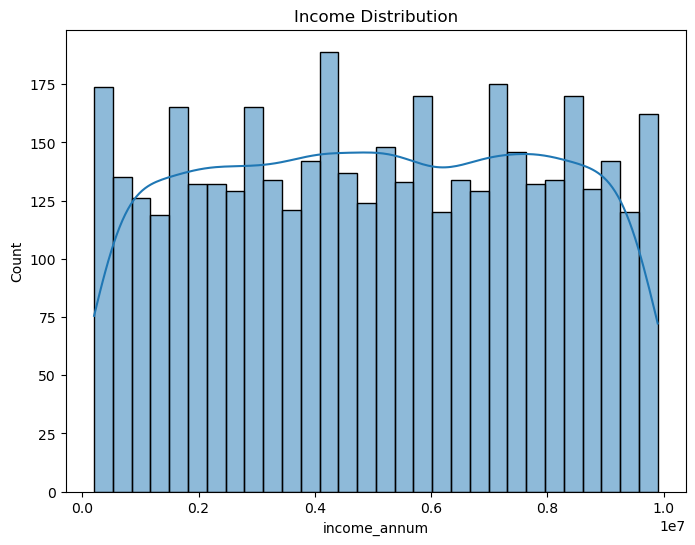

In [52]:
# histogram of income distribution
plt.figure(figsize=(8, 6))
sns.histplot(df['income_annum'], bins=30, kde=True)
plt.title('Income Distribution')
plt.show()


#### This chart shows how people’s incomes are spread out. The bars are fairly even, meaning incomes vary widely without one range standing out. In simple terms, people earn very different amounts, and there’s no clear pattern or common income level.

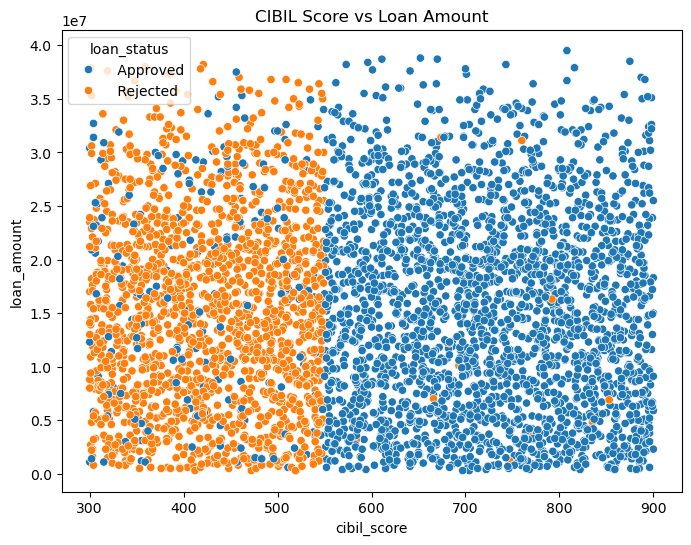

In [53]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='cibil_score', y='loan_amount', hue='loan_status', data=df)
plt.title('CIBIL Score vs Loan Amount')
plt.show()


#### This scatter plot shows how CIBIL scores relate to loan approvals and rejections. People with higher scores (above ~600) mostly have approved loans (blue dots), while those with lower scores (below ~600) tend to be rejected (orange dots). The loan amounts vary widely across both groups, but the clear split shows that a good credit score strongly increases the chance of loan approval.